# Taller 2 — Experimento complementario: DQN, Double DQN y Dueling DQN en Acrobot-v1

Este notebook complementa a `Taller2_DQN_Acrobot.ipynb`. Allí entrenamos DQN con Stable-Baselines3. Aquí implementamos DQN directamente en PyTorch, tomando como base el código de los capítulos 6 y 8 del libro de Lapan, y lo usamos para comparar cuatro agentes en las mismas condiciones:

- DQN de Stable-Baselines3 (referencia)
- DQN propio
- Double DQN
- Dueling DQN

Cada agente se entrena con las semillas 42, 25 y 123 durante 100.000 timesteps y se evalúa en 30 episodios por semilla. Para la evaluación usamos semillas que no se usaron ni en el entrenamiento ni en el baseline. Cada corrida guarda sus registros en una carpeta propia.

## 0. Instalación y configuración

La celda de instalación solo hace falta la primera vez. Con `MODO_RAPIDO = True` se hace una prueba corta; los resultados de este notebook se obtuvieron con `MODO_RAPIDO = False` (12 entrenamientos, unos 25 minutos en CPU).

In [4]:
# !pip install "gymnasium[classic-control]" "stable-baselines3[extra]" torch pandas matplotlib

In [8]:
import json, time, platform
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import stable_baselines3
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor

ENV_ID = "Acrobot-v1"
MODO_RAPIDO = False           # True = prueba corta
EJECUTAR_SB3 = True           # entrenamiento con Stable-Baselines3
EJECUTAR_PROPIO = True        # DQN / Double / Dueling en PyTorch

SEEDS = [42] if MODO_RAPIDO else [42, 25, 123]
TOTAL_TIMESTEPS = 20_000 if MODO_RAPIDO else 100_000
N_EVAL_EPISODES = 10 if MODO_RAPIDO else 30

# Semillas disjuntas: entrenamiento usa SEEDS, baseline y evaluación usan rangos propios
BASELINE_SEED_OFFSET = 20_000
EVAL_SEED_OFFSET = 10_000

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
DEVICE = "cpu"   # para un MLP pequeño la CPU suele ser más rápida que la GPU

print("Python", platform.python_version(), "| gymnasium", gym.__version__,
      "| SB3", stable_baselines3.__version__, "| torch", torch.__version__)

Python 3.12.11 | gymnasium 1.4.0 | SB3 2.9.0 | torch 2.13.0


## 1. Hiperparámetros

Se parte de los hiperparámetros publicados en **RL Baselines3 Zoo** para `Acrobot-v1` con DQN. La implementación propia usa exactamente los mismos para que la comparación sea justa.

| Hiperparámetro | Valor | Para qué sirve |
|---|---|---|
| `learning_rate` | 6.3e-4 | Tamaño del paso de Adam |
| `buffer_size` | 50 000 | Transiciones guardadas en el replay buffer |
| `learning_starts` | 1 000 | Pasos de solo exploración antes de entrenar (la v1 usaba 0: se entrenaba con un buffer casi vacío) |
| `batch_size` | 128 | Transiciones por actualización |
| `gamma` | 0.99 | Factor de descuento (horizonte efectivo ≈ 100 pasos) |
| `target_update_interval` | 250 | Cada cuántos pasos se copia la red online en la red objetivo |
| `train_freq` / `gradient_steps` | 4 / 4 | Cada 4 pasos de interacción se hacen 4 actualizaciones (≈1 por paso) |
| `exploration_fraction` | 0.12 | Fracción del entrenamiento en que ε baja linealmente |
| ε inicial → final | 1.0 → 0.1 | Exploración ε-greedy |
| `net_arch` | [256, 256] | Capas ocultas del MLP |
| `max_grad_norm` | 10 | Recorte del gradiente (estabilidad) |

In [9]:
HP = {
    "learning_rate": 6.3e-4,
    "buffer_size": 50_000,
    "learning_starts": 1_000,
    "batch_size": 128,
    "gamma": 0.99,
    "target_update_interval": 250,
    "train_freq": 4,
    "gradient_steps": 4,
    "exploration_fraction": 0.12,
    "exploration_initial_eps": 1.0,
    "exploration_final_eps": 0.10,
    "net_arch": [256, 256],
    "max_grad_norm": 10.0,
    "total_timesteps": TOTAL_TIMESTEPS,
}

with open(RESULTS_DIR / "run_config.json", "w") as f:
    json.dump({"env_id": ENV_ID, "seeds": SEEDS, "n_eval_episodes": N_EVAL_EPISODES,
               "eval_seed_offset": EVAL_SEED_OFFSET, "baseline_seed_offset": BASELINE_SEED_OFFSET,
               "hyperparameters": HP}, f, indent=2)
HP

{'learning_rate': 0.00063,
 'buffer_size': 50000,
 'learning_starts': 1000,
 'batch_size': 128,
 'gamma': 0.99,
 'target_update_interval': 250,
 'train_freq': 4,
 'gradient_steps': 4,
 'exploration_fraction': 0.12,
 'exploration_initial_eps': 1.0,
 'exploration_final_eps': 0.1,
 'net_arch': [256, 256],
 'max_grad_norm': 10.0,
 'total_timesteps': 100000}

## 2. El ambiente: observaciones, acciones y recompensa

`Acrobot-v1` es un péndulo doble con un solo motor en la articulación del medio. El objetivo es que el extremo libre suba por encima de una línea: altura $-\cos\theta_1 - \cos(\theta_1+\theta_2) > 1$.

**Observación** (`Box(6)`, continua): $[\cos\theta_1, \sin\theta_1, \cos\theta_2, \sin\theta_2, \dot\theta_1, \dot\theta_2]$. Se usan seno y coseno en lugar del ángulo para evitar el salto de $-\pi$ a $\pi$. Las velocidades están acotadas a $\pm 4\pi$ y $\pm 9\pi$ rad/s.

**Acciones** (`Discrete(3)`): torque $-1$, $0$, $+1$ en la articulación actuada. Al ser discretas y pocas, DQN encaja bien: la red produce un valor Q por acción y se elige el máximo.

**Recompensa:** $-1$ por cada paso hasta llegar a la meta (0 en el paso que la alcanza). Por eso *retorno = −(pasos − 1)* cuando hay éxito y el mejor agente es el más rápido.

**Fin de episodio:**
- `terminated = True` → se alcanzó la meta (estado terminal real).
- `truncated = True` → se llegó a 500 pasos (límite de tiempo, **no** es terminal).

Esta diferencia importa en DQN: si se trata la truncación como terminal, el objetivo de Bellman pone $V(s')=0$ en un estado que no lo es.

El ambiente se considera "resuelto" en la literatura con un retorno promedio de alrededor de −100.

In [10]:
env = gym.make(ENV_ID)
print("Espacio de observación:", env.observation_space)
print("  low :", np.round(env.observation_space.low, 2))
print("  high:", np.round(env.observation_space.high, 2))
print("Espacio de acciones   :", env.action_space)
print("Límite de pasos       :", env.spec.max_episode_steps)
obs, info = env.reset(seed=0)
print("Observación inicial   :", np.round(obs, 3))
env.close()

Espacio de observación: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
  low : [ -1.    -1.    -1.    -1.   -12.57 -28.27]
  high: [ 1.    1.    1.    1.   12.57 28.27]
Espacio de acciones   : Discrete(3)
Límite de pasos       : 500
Observación inicial   : [ 1.     0.027  0.999 -0.046 -0.092 -0.097]


### 2.1 Línea base: política aleatoria

Sirve de referencia para saber si el agente aprendió algo. Se evalúa con semillas distintas a las de entrenamiento y evaluación.

In [11]:
def run_episodes(policy_fn, n_episodes, seed_offset, label):
    # Ejecuta n episodios con policy_fn(obs) -> acción y devuelve un DataFrame
    rows = []
    for ep in range(n_episodes):
        env = gym.make(ENV_ID)
        obs, _ = env.reset(seed=seed_offset + ep)
        env.action_space.seed(seed_offset + ep)
        done, ret, length = False, 0.0, 0
        while not done:
            action = policy_fn(obs, env)
            obs, r, terminated, truncated, _ = env.step(action)
            ret += float(r); length += 1
            done = terminated or truncated
        rows.append({"agente": label, "episodio": ep + 1, "retorno": ret,
                     "longitud": length, "exito": int(terminated)})
        env.close()
    return pd.DataFrame(rows)

baseline_df = run_episodes(lambda obs, env: env.action_space.sample(),
                           N_EVAL_EPISODES, BASELINE_SEED_OFFSET, "Aleatorio")
baseline_df.to_csv(RESULTS_DIR / "baseline_random.csv", index=False)
baseline_df[["retorno", "longitud", "exito"]].describe().round(2)

,retorno,longitud,exito
count,30.00,30.00,30.00
mean,-496.67,496.70,0.03
std,18.26,18.07,0.18
min,-500.00,401.00,0.00
25%,-500.00,500.00,0.00
50%,-500.00,500.00,0.00
75%,-500.00,500.00,0.00
max,-400.00,500.00,1.00


## 3. Flujo de DQN

DQN aproxima la función acción-valor $Q(s,a)$ con una red neuronal y la entrena con la ecuación de Bellman de optimalidad (Mnih et al., 2013; Sutton & Barto, cap. 6.5 y 9).

```
inicializar red online Q_θ y red objetivo Q_θ⁻ ← Q_θ, replay buffer D vacío
para t = 1 … T:
    ε ← calendario lineal(t)
    a ← acción aleatoria con prob. ε, si no argmax_a Q_θ(s, a)
    s', r, terminated, truncated ← env.step(a)
    guardar (s, a, r, s', terminated) en D          # truncated NO se guarda como terminal
    si terminated o truncated: s ← env.reset()  si no: s ← s'
    si t > learning_starts y t % train_freq == 0:
        repetir gradient_steps veces:
            muestrear minibatch de D
            y = r + γ (1 − terminated) · max_a' Q_θ⁻(s', a')
            pérdida = Huber(Q_θ(s, a), y);  paso de Adam con recorte de gradiente
    si t % target_update_interval == 0:  θ⁻ ← θ
```

**Particularidades que hacen que funcione**
- **Replay buffer:** rompe la correlación entre transiciones consecutivas y reutiliza experiencia.
- **Red objetivo:** congela el objetivo $y$ durante 250 pasos; sin ella se persigue un blanco que se mueve en cada actualización.
- **ε-greedy con decaimiento:** mucha exploración al inicio (ε=1) y poca al final (ε=0.1).
- **Pérdida de Huber:** se comporta como MSE para errores pequeños y como L1 para grandes; evita gradientes explosivos.
- **Off-policy:** aprende de la política greedy mientras actúa con ε-greedy.

**Variantes que se comparan (implementación propia)**
- **Double DQN** (van Hasselt et al., 2015): la red online elige la acción y la objetivo la evalúa, $y = r + γ\,Q_{θ^-}(s', \arg\max_{a'} Q_θ(s',a'))$. Reduce la sobreestimación de valores Q.
- **Dueling DQN** (Wang et al., 2016): separa $Q(s,a) = V(s) + A(s,a) - \frac{1}{|A|}\sum_{a'} A(s,a')$. Útil cuando en muchos estados la acción importa poco.

## 4. Red neuronal

Entrada de 6 valores → `Linear(6,256)` → ReLU → `Linear(256,256)` → ReLU → `Linear(256,3)` (un valor Q por acción). Total ≈ 68 600 parámetros.

En la variante *Dueling* las dos capas ocultas son compartidas y la salida se divide en una cabeza $V(s)$ (1 neurona) y una cabeza $A(s,a)$ (3 neuronas).

No se usan convoluciones porque la observación es un vector pequeño de variables físicas, no una imagen.

In [12]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=(256, 256), dueling=False):
        super().__init__()
        self.dueling = dueling
        self.body = nn.Sequential(nn.Linear(obs_dim, hidden[0]), nn.ReLU(),
                                  nn.Linear(hidden[0], hidden[1]), nn.ReLU())
        if dueling:
            self.value = nn.Linear(hidden[1], 1)
            self.advantage = nn.Linear(hidden[1], n_actions)
        else:
            self.q = nn.Linear(hidden[1], n_actions)

    def forward(self, x):
        z = self.body(x)
        if self.dueling:
            a = self.advantage(z)
            return self.value(z) + a - a.mean(dim=1, keepdim=True)
        return self.q(z)

for dueling in (False, True):
    net = QNetwork(6, 3, tuple(HP["net_arch"]), dueling)
    print(f"dueling={dueling}:", sum(p.numel() for p in net.parameters()), "parámetros")
print(QNetwork(6, 3, tuple(HP["net_arch"])))

dueling=False: 68355 parámetros
dueling=True: 68612 parámetros
QNetwork(
  (body): Sequential(
    (0): Linear(in_features=6, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
  )
  (q): Linear(in_features=256, out_features=3, bias=True)
)


## 5. Implementación propia de DQN (PyTorch)

Adaptada del libro *Deep Reinforcement Learning Hands-On* (Lapan, 3.ª ed., cap. 6 `02_dqn_pong.py` y cap. 8 `03_dqn_double.py`, `lib/dqn_extra.py`) a un ambiente con observación vectorial. Reproduce la lógica de SB3 (mismos hiperparámetros, Huber, recorte de gradiente) y añade los interruptores `double` y `dueling`.

In [13]:
class ReplayBuffer:
    def __init__(self, capacity, obs_dim):
        self.capacity, self.idx, self.full = capacity, 0, False
        self.obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.terminated = np.zeros(capacity, dtype=np.float32)

    def add(self, o, a, r, o2, term):
        i = self.idx
        self.obs[i], self.actions[i], self.rewards[i] = o, a, r
        self.next_obs[i], self.terminated[i] = o2, float(term)
        self.idx = (self.idx + 1) % self.capacity
        self.full = self.full or self.idx == 0

    def __len__(self):
        return self.capacity if self.full else self.idx

    def sample(self, batch_size, rng):
        ix = rng.integers(0, len(self), size=batch_size)
        t = lambda x: torch.as_tensor(x[ix], device=DEVICE)
        return t(self.obs), t(self.actions), t(self.rewards), t(self.next_obs), t(self.terminated)


def epsilon_at(step, hp):
    frac = min(1.0, step / (hp["exploration_fraction"] * hp["total_timesteps"]))
    return hp["exploration_initial_eps"] + frac * (hp["exploration_final_eps"] - hp["exploration_initial_eps"])


def train_custom_dqn(seed, hp, double=False, dueling=False, label="DQN"):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    env = gym.make(ENV_ID)
    obs, _ = env.reset(seed=seed)
    env.action_space.seed(seed)
    obs_dim, n_actions = env.observation_space.shape[0], env.action_space.n

    online = QNetwork(obs_dim, n_actions, tuple(hp["net_arch"]), dueling).to(DEVICE)
    target = QNetwork(obs_dim, n_actions, tuple(hp["net_arch"]), dueling).to(DEVICE)
    target.load_state_dict(online.state_dict())
    optimizer = torch.optim.Adam(online.parameters(), lr=hp["learning_rate"])
    buffer = ReplayBuffer(hp["buffer_size"], obs_dim)

    episodes, losses, q_means = [], [], []
    ep_ret, ep_len = 0.0, 0
    t0 = time.time()

    for step in range(1, hp["total_timesteps"] + 1):
        eps = epsilon_at(step, hp)
        if rng.random() < eps:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                action = int(online(torch.as_tensor(obs, device=DEVICE).unsqueeze(0)).argmax(1).item())

        next_obs, reward, terminated, truncated, _ = env.step(action)
        buffer.add(obs, action, reward, next_obs, terminated)   # la truncación NO es terminal
        ep_ret += reward; ep_len += 1
        obs = next_obs

        if terminated or truncated:
            episodes.append({"timestep": step, "retorno": ep_ret, "longitud": ep_len,
                             "exito": int(terminated), "epsilon": eps})
            obs, _ = env.reset()
            ep_ret, ep_len = 0.0, 0

        if step > hp["learning_starts"] and step % hp["train_freq"] == 0:
            for _ in range(hp["gradient_steps"]):
                s, a, r, s2, term = buffer.sample(hp["batch_size"], rng)
                with torch.no_grad():
                    if double:   # online elige, target evalúa
                        a2 = online(s2).argmax(dim=1, keepdim=True)
                        q_next = target(s2).gather(1, a2).squeeze(1)
                    else:        # target elige y evalúa
                        q_next = target(s2).max(dim=1).values
                    y = r + hp["gamma"] * (1.0 - term) * q_next
                q_sa = online(s).gather(1, a.unsqueeze(1)).squeeze(1)
                loss = F.smooth_l1_loss(q_sa, y)
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(online.parameters(), hp["max_grad_norm"])
                optimizer.step()
            losses.append({"timestep": step, "loss": loss.item(), "q_medio": q_sa.mean().item()})

        if step % hp["target_update_interval"] == 0:
            target.load_state_dict(online.state_dict())

    env.close()
    online.eval()
    info = {"agente": label, "semilla": seed, "segundos": time.time() - t0}
    return online, pd.DataFrame(episodes), pd.DataFrame(losses), info

## 6. Entrenamiento

### 6.1 Stable-Baselines3 (implementación de referencia)

Cada semilla escribe su `Monitor` en una carpeta propia (`results/sb3/seed_<n>/`), por lo que la curva de aprendizaje de una corrida no se mezcla con la de otra.

In [14]:
def train_sb3(seed, hp):
    log_dir = RESULTS_DIR / "sb3" / f"seed_{seed}"
    log_dir.mkdir(parents=True, exist_ok=True)
    env = Monitor(gym.make(ENV_ID), str(log_dir / "monitor"))
    model = DQN("MlpPolicy", env,
                learning_rate=hp["learning_rate"], buffer_size=hp["buffer_size"],
                learning_starts=hp["learning_starts"], batch_size=hp["batch_size"],
                gamma=hp["gamma"], target_update_interval=hp["target_update_interval"],
                train_freq=hp["train_freq"], gradient_steps=hp["gradient_steps"],
                exploration_fraction=hp["exploration_fraction"],
                exploration_initial_eps=hp["exploration_initial_eps"],
                exploration_final_eps=hp["exploration_final_eps"],
                max_grad_norm=hp["max_grad_norm"],
                policy_kwargs={"net_arch": hp["net_arch"]},
                seed=seed, verbose=0, device=DEVICE)
    t0 = time.time()
    model.learn(total_timesteps=hp["total_timesteps"])
    secs = time.time() - t0
    env.close()
    model.save(log_dir / "model")
    mon = pd.read_csv(log_dir / "monitor.monitor.csv", skiprows=1)   # columnas r, l, t
    episodes = pd.DataFrame({"timestep": mon["l"].cumsum(), "retorno": mon["r"],
                             "longitud": mon["l"]})
    return model, episodes, {"agente": "SB3 DQN", "semilla": seed, "segundos": secs}

modelos, curvas, perdidas, tiempos = {}, [], [], []

if EJECUTAR_SB3:
    for seed in SEEDS:
        print(f"SB3 DQN · semilla {seed} ...", end=" ", flush=True)
        model, ep_df, info = train_sb3(seed, HP)
        modelos[("SB3 DQN", seed)] = model
        curvas.append(ep_df.assign(agente="SB3 DQN", semilla=seed))
        tiempos.append(info)
        print(f"{info['segundos']:.0f} s")

SB3 DQN · semilla 42 ... 116 s
SB3 DQN · semilla 25 ... 119 s
SB3 DQN · semilla 123 ... 119 s


### 6.2 Implementación propia: DQN, Double DQN y Dueling DQN

In [15]:
VARIANTES = {
    "DQN propio": dict(double=False, dueling=False),
    "Double DQN": dict(double=True, dueling=False),
    "Dueling DQN": dict(double=False, dueling=True),
}

if EJECUTAR_PROPIO:
    for label, flags in VARIANTES.items():
        for seed in SEEDS:
            print(f"{label} · semilla {seed} ...", end=" ", flush=True)
            net, ep_df, loss_df, info = train_custom_dqn(seed, HP, label=label, **flags)
            modelos[(label, seed)] = net
            curvas.append(ep_df.assign(agente=label, semilla=seed))
            perdidas.append(loss_df.assign(agente=label, semilla=seed))
            tiempos.append(info)
            torch.save(net.state_dict(), RESULTS_DIR / f"{label.replace(' ', '_')}_seed{seed}.pt")
            print(f"{info['segundos']:.0f} s")

curvas_df = pd.concat(curvas, ignore_index=True)
curvas_df.to_csv(RESULTS_DIR / "curvas_entrenamiento.csv", index=False)
if perdidas:
    perdidas_df = pd.concat(perdidas, ignore_index=True)
    perdidas_df.to_csv(RESULTS_DIR / "perdidas_entrenamiento.csv", index=False)
tiempos_df = pd.DataFrame(tiempos)
tiempos_df.to_csv(RESULTS_DIR / "tiempos_entrenamiento.csv", index=False)
tiempos_df.groupby("agente")["segundos"].mean().round(1)

DQN propio · semilla 42 ... 112 s
DQN propio · semilla 25 ... 110 s
DQN propio · semilla 123 ... 115 s
Double DQN · semilla 42 ... 111 s
Double DQN · semilla 25 ... 106 s
Double DQN · semilla 123 ... 109 s
Dueling DQN · semilla 42 ... 121 s
Dueling DQN · semilla 25 ... 125 s
Dueling DQN · semilla 123 ... 122 s


agente
DQN propio     112.7
Double DQN     109.0
Dueling DQN    122.7
SB3 DQN        118.0
Name: segundos, dtype: float64

## 7. Curvas de aprendizaje

Para promediar semillas se interpola el retorno (media móvil de 20 episodios) sobre una malla común de pasos. La línea es la media entre semillas y la banda el mínimo–máximo entre semillas.

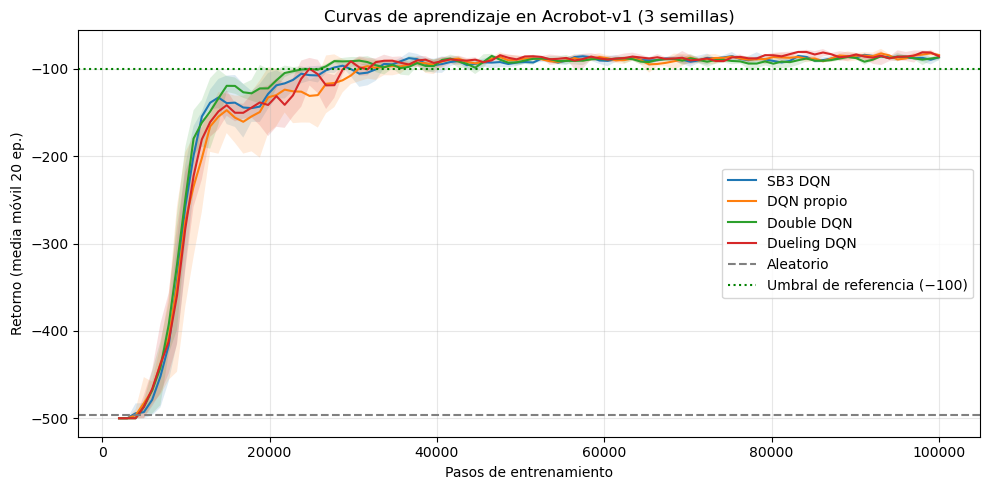

In [16]:
GRID = np.linspace(2_000, TOTAL_TIMESTEPS, 100)

def curva_interpolada(df, window=20):
    df = df.sort_values("timestep")
    smooth = df["retorno"].rolling(window, min_periods=1).mean()
    return np.interp(GRID, df["timestep"], smooth)

agentes = list(curvas_df["agente"].unique())
fig, ax = plt.subplots(figsize=(10, 5))
for agente in agentes:
    sub = curvas_df[curvas_df["agente"] == agente]
    Y = np.vstack([curva_interpolada(g) for _, g in sub.groupby("semilla")])
    ax.plot(GRID, Y.mean(0), label=agente)
    ax.fill_between(GRID, Y.min(0), Y.max(0), alpha=0.15)
ax.axhline(baseline_df["retorno"].mean(), color="gray", ls="--", label="Aleatorio")
ax.axhline(-100, color="green", ls=":", label="Umbral de referencia (−100)")
ax.set(xlabel="Pasos de entrenamiento", ylabel="Retorno (media móvil 20 ep.)",
       title=f"Curvas de aprendizaje en {ENV_ID} ({len(SEEDS)} semillas)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "curvas_aprendizaje.png", dpi=200); plt.show()

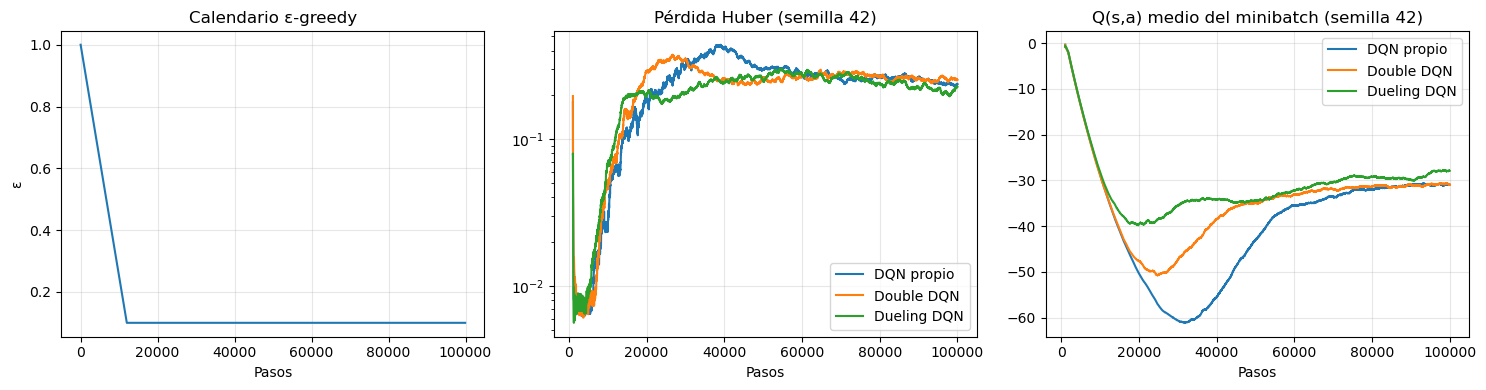

In [17]:
# Calendario de ε y pérdida / valor Q medio de la implementación propia
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
steps = np.arange(1, TOTAL_TIMESTEPS + 1, 100)
axes[0].plot(steps, [epsilon_at(s, HP) for s in steps])
axes[0].set(title="Calendario ε-greedy", xlabel="Pasos", ylabel="ε")
if perdidas:
    for agente, sub in perdidas_df.groupby("agente"):
        s = sub[sub["semilla"] == SEEDS[0]].sort_values("timestep")
        axes[1].plot(s["timestep"], s["loss"].rolling(200, min_periods=1).mean(), label=agente)
        axes[2].plot(s["timestep"], s["q_medio"].rolling(200, min_periods=1).mean(), label=agente)
    axes[1].set(title=f"Pérdida Huber (semilla {SEEDS[0]})", xlabel="Pasos", yscale="log")
    axes[2].set(title=f"Q(s,a) medio del minibatch (semilla {SEEDS[0]})", xlabel="Pasos")
    axes[1].legend(); axes[2].legend()
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "epsilon_perdida_q.png", dpi=200); plt.show()

Para interpretar el Q medio: con recompensa -1 por paso y γ = 0,99, un estado que está a *k* pasos de la meta vale $-(1-γ^k)/(1-γ)$. Si se promedia sobre todos los estados de un episodio de unos 80 pasos, el valor esperado es cercano a -31,6. Las tres variantes terminan entre -28 y -31, así que no se observa sobreestimación. La caída del DQN hasta -61 alrededor de 30.000 pasos coincide con el momento en que el buffer todavía tenía muchas transiciones de episodios largos.

## 8. Evaluación

Cada modelo se evalúa con política **greedy** (`deterministic=True`, sin ε) durante `N_EVAL_EPISODES` episodios cuyas semillas (`10 000 + i`) no se usaron ni para entrenar ni para el baseline.

In [18]:
def politica(agente, modelo):
    if agente == "SB3 DQN":
        return lambda obs, env: int(modelo.predict(obs, deterministic=True)[0])
    def greedy(obs, env):
        with torch.no_grad():
            return int(modelo(torch.as_tensor(obs, device=DEVICE).unsqueeze(0)).argmax(1).item())
    return greedy

evals = []
for (agente, seed), modelo in modelos.items():
    df = run_episodes(politica(agente, modelo), N_EVAL_EPISODES, EVAL_SEED_OFFSET, agente)
    evals.append(df.assign(semilla=seed))
eval_df = pd.concat(evals, ignore_index=True)
eval_df.to_csv(RESULTS_DIR / "evaluacion_episodios.csv", index=False)

por_semilla = (eval_df.groupby(["agente", "semilla"])
               .agg(retorno_medio=("retorno", "mean"), retorno_std=("retorno", "std"),
                    retorno_min=("retorno", "min"), retorno_max=("retorno", "max"),
                    longitud_media=("longitud", "mean"), tasa_exito=("exito", "mean"))
               .reset_index())
por_semilla.to_csv(RESULTS_DIR / "evaluacion_por_semilla.csv", index=False)
por_semilla.round(2)

,agente,semilla,retorno_medio,retorno_std,retorno_min,retorno_max,longitud_media,tasa_exito
0,DQN propio,25,-79.10,11.49,-113.0,-62.0,80.10,1.0
1,DQN propio,42,-79.27,15.77,-141.0,-63.0,80.27,1.0
2,DQN propio,123,-79.23,10.47,-107.0,-62.0,80.23,1.0
3,Double DQN,25,-81.73,12.54,-109.0,-62.0,82.73,1.0
4,Double DQN,42,-83.27,13.45,-114.0,-62.0,84.27,1.0
5,Double DQN,123,-123.00,128.77,-500.0,-62.0,123.90,0.9
6,Dueling DQN,25,-73.83,10.79,-103.0,-62.0,74.83,1.0
7,Dueling DQN,42,-71.87,8.63,-96.0,-62.0,72.87,1.0
8,Dueling DQN,123,-73.53,7.64,-94.0,-62.0,74.53,1.0
9,SB3 DQN,25,-77.70,13.99,-117.0,-62.0,78.70,1.0


In [19]:
# Agregado entre semillas con IC 95 % (t de Student sobre las medias por semilla)
T_975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306, 9: 2.262}

def agregar(g):
    m = g["retorno_medio"]; n = len(m)
    half = T_975.get(n - 1, 1.96) * m.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return pd.Series({"n_semillas": n, "retorno_medio": m.mean(), "std_entre_semillas": m.std(ddof=1),
                      "ic95_inf": m.mean() - half, "ic95_sup": m.mean() + half,
                      "peor_episodio": g["retorno_min"].min(), "longitud_media": g["longitud_media"].mean(),
                      "tasa_exito": g["tasa_exito"].mean()})

agregado = por_semilla.groupby("agente").apply(agregar, include_groups=False).reset_index()
base = baseline_df.agg({"retorno": "mean", "longitud": "mean", "exito": "mean"})
agregado["mejora_vs_aleatorio"] = agregado["retorno_medio"] - base["retorno"]
agregado = agregado.sort_values("retorno_medio", ascending=False)
agregado.to_csv(RESULTS_DIR / "evaluacion_agregada.csv", index=False)
print(f"Aleatorio: retorno {base['retorno']:.2f}, longitud {base['longitud']:.1f}, éxito {base['exito']:.0%}")
agregado.round(2)

Aleatorio: retorno -496.67, longitud 496.7, éxito 3%


,agente,n_semillas,retorno_medio,std_entre_semillas,ic95_inf,ic95_sup,peor_episodio,longitud_media,tasa_exito,mejora_vs_aleatorio
2,Dueling DQN,3.0,-73.08,1.06,-75.71,-70.45,-103.0,74.08,1.00,423.59
3,SB3 DQN,3.0,-79.11,5.13,-91.86,-66.36,-117.0,80.11,1.00,417.56
0,DQN propio,3.0,-79.20,0.09,-79.42,-78.98,-141.0,80.20,1.00,417.47
1,Double DQN,3.0,-96.00,23.40,-154.12,-37.88,-500.0,96.97,0.97,400.67


## 9. Visualización de resultados

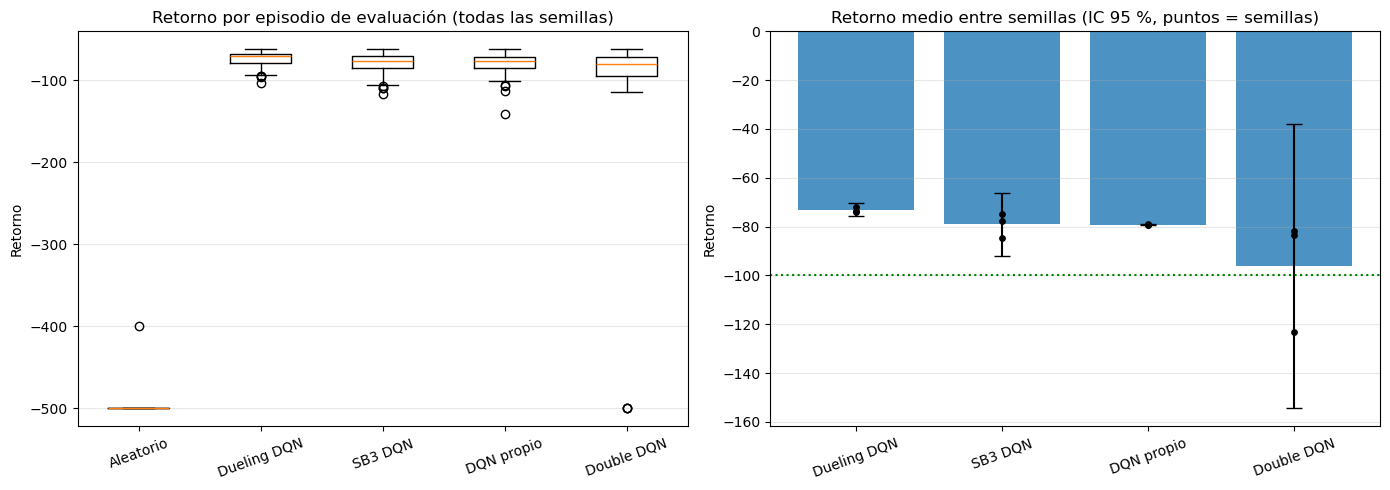

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
orden = ["Aleatorio"] + list(agregado["agente"])
datos = [baseline_df["retorno"]] + [eval_df.loc[eval_df["agente"] == a, "retorno"] for a in agregado["agente"]]
axes[0].boxplot(datos)
axes[0].set_xticks(range(1, len(orden) + 1), orden)
axes[0].set(title="Retorno por episodio de evaluación (todas las semillas)", ylabel="Retorno")
axes[0].tick_params(axis="x", rotation=20)

x = np.arange(len(agregado))
err = np.vstack([agregado["retorno_medio"] - agregado["ic95_inf"], agregado["ic95_sup"] - agregado["retorno_medio"]])
axes[1].bar(x, agregado["retorno_medio"], yerr=np.nan_to_num(err), capsize=6, alpha=0.8)
for i, a in enumerate(agregado["agente"]):
    pts = por_semilla.loc[por_semilla["agente"] == a, "retorno_medio"]
    axes[1].scatter(np.full(len(pts), i), pts, color="black", zorder=3, s=15)
axes[1].axhline(-100, color="green", ls=":")
axes[1].set_xticks(x, agregado["agente"], rotation=20)
axes[1].set(title="Retorno medio entre semillas (IC 95 %, puntos = semillas)", ylabel="Retorno")
for a in axes: a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "comparacion_agentes.png", dpi=200); plt.show()

In [23]:
# (Opcional) GIF de un episodio del mejor agente. Requiere: pip install imageio
try:
    import imageio
    mejor = agregado.iloc[0]["agente"]
    seed_mejor = por_semilla[por_semilla["agente"] == mejor].sort_values("retorno_medio").iloc[-1]["semilla"]
    pol = politica(mejor, modelos[(mejor, int(seed_mejor))])
    env = gym.make(ENV_ID, render_mode="rgb_array")
    obs, _ = env.reset(seed=EVAL_SEED_OFFSET)
    frames, done = [env.render()], False
    while not done:
        obs, r, term, trunc, _ = env.step(pol(obs, env))
        frames.append(env.render()); done = term or trunc
    env.close()
    imageio.mimsave(RESULTS_DIR / "acrobot_mejor_agente.gif", frames, duration=1 / 30)
    print(f"GIF guardado ({len(frames)} cuadros) — {mejor}, semilla {int(seed_mejor)}")
except ImportError:
    print("imageio no está instalado; se omite el GIF")

GIF guardado (65 cuadros) — Dueling DQN, semilla 42


## 10. Reflexión sobre los resultados

La siguiente celda guarda en `results/resumen_resultados.md` las tablas con los resultados de esta ejecución.

In [24]:
def fmt(x, d=2): return f"{x:.{d}f}"

lines = [f"# Resumen de resultados — {ENV_ID}", "",
         f"Semillas de entrenamiento: {SEEDS} · pasos: {TOTAL_TIMESTEPS:,} · episodios de evaluación por semilla: {N_EVAL_EPISODES}", "",
         f"Política aleatoria: retorno medio {fmt(base['retorno'])}, longitud {fmt(base['longitud'],1)}, éxito {base['exito']:.0%}", "",
         "| Agente | Retorno medio | IC 95 % | Std entre semillas | Peor episodio | Longitud media | Éxito | Mejora vs aleatorio |",
         "|---|---|---|---|---|---|---|---|"]
for _, r in agregado.iterrows():
    lines.append(f"| {r['agente']} | {fmt(r['retorno_medio'])} | [{fmt(r['ic95_inf'])}, {fmt(r['ic95_sup'])}] | "
                 f"{fmt(r['std_entre_semillas'])} | {fmt(r['peor_episodio'],0)} | {fmt(r['longitud_media'],1)} | "
                 f"{r['tasa_exito']:.0%} | {fmt(r['mejora_vs_aleatorio'])} |")
lines += ["", "## Por semilla", "", "| Agente | Semilla | Retorno medio ± std | Mín | Máx | Longitud | Éxito |", "|---|---|---|---|---|---|---|"]
for _, r in por_semilla.iterrows():
    lines.append(f"| {r['agente']} | {r['semilla']} | {fmt(r['retorno_medio'])} ± {fmt(r['retorno_std'])} | "
                 f"{fmt(r['retorno_min'],0)} | {fmt(r['retorno_max'],0)} | {fmt(r['longitud_media'],1)} | {r['tasa_exito']:.0%} |")

# Lectura automática para apoyar la reflexión
mejor, peor = agregado.iloc[0], agregado.iloc[-1]
solapan = mejor["ic95_inf"] <= peor["ic95_sup"]
lines += ["", "## Lectura automática", "",
          f"- Mejor agente: **{mejor['agente']}** ({fmt(mejor['retorno_medio'])}); peor: {peor['agente']} ({fmt(peor['retorno_medio'])}).",
          f"- Los IC 95 % del mejor y el peor {'se solapan: con estas semillas la diferencia NO es concluyente' if solapan else 'no se solapan: la diferencia es consistente entre semillas'}.",
          f"- Todos los agentes superan el umbral de −100: {'sí' if (agregado['retorno_medio'] > -100).all() else 'no'}."]
texto = "\n".join(lines)
(RESULTS_DIR / "resumen_resultados.md").write_text(texto, encoding="utf-8")
print(texto)

# Resumen de resultados — Acrobot-v1

Semillas de entrenamiento: [42, 25, 123] · pasos: 100,000 · episodios de evaluación por semilla: 30

Política aleatoria: retorno medio -496.67, longitud 496.7, éxito 3%

| Agente | Retorno medio | IC 95 % | Std entre semillas | Peor episodio | Longitud media | Éxito | Mejora vs aleatorio |
|---|---|---|---|---|---|---|---|
| Dueling DQN | -73.08 | [-75.71, -70.45] | 1.06 | -103 | 74.1 | 100% | 423.59 |
| SB3 DQN | -79.11 | [-91.86, -66.36] | 5.13 | -117 | 80.1 | 100% | 417.56 |
| DQN propio | -79.20 | [-79.42, -78.98] | 0.09 | -141 | 80.2 | 100% | 417.47 |
| Double DQN | -96.00 | [-154.12, -37.88] | 23.40 | -500 | 97.0 | 97% | 400.67 |

## Por semilla

| Agente | Semilla | Retorno medio ± std | Mín | Máx | Longitud | Éxito |
|---|---|---|---|---|---|---|
| DQN propio | 25 | -79.10 ± 11.49 | -113 | -62 | 80.1 | 100% |
| DQN propio | 42 | -79.27 ± 15.77 | -141 | -63 | 80.3 | 100% |
| DQN propio | 123 | -79.23 ± 10.47 | -107 | -62 | 80.2 | 100% |
| Do

Los cuatro agentes aprendieron a resolver el ambiente. Todos pasan de -500 a menos de -100 en unos 30.000 a 40.000 timesteps, y en la evaluación resuelven entre el 97 % y el 100 % de los episodios, frente al 3 % de la política aleatoria.

Nuestra implementación de DQN da prácticamente lo mismo que Stable-Baselines3 (-79,20 frente a -79,11) y las curvas de aprendizaje se superponen. Eso nos indica que la implementación es correcta y que el resultado depende del algoritmo, no de la librería.

Dueling DQN fue el mejor agente: -73,08, unos 6 pasos menos por episodio que el DQN propio y con muy poca diferencia entre semillas. Su intervalo de confianza no se cruza con el del DQN propio. Creemos que esto se debe a que en Acrobot hay muchos estados donde la acción inmediata importa poco, y la arquitectura dueling aprende el valor del estado con todas las transiciones.

Double DQN no mejoró el resultado. Con las semillas 42 y 25 quedó cerca del DQN, pero con la semilla 123 tres de los 30 episodios se quedaron en -500 y el promedio bajó a -123. Con un intervalo tan amplio no podemos afirmar que sea peor, solo que en este ambiente no aportó. Esto es coherente con lo que vemos en el Q medio: no hay sobreestimación que corregir.

Un detalle que se repite en todos los agentes es que el mejor episodio queda en -62. Parece ser cercano al mínimo de pasos que permite la física del problema con un torque de ±1.

## 11. Reflexión sobre las dificultades

- **Variación entre semillas.** La misma configuración puede dar resultados distintos según la semilla. El caso más claro fue Double DQN con la semilla 123. Por eso reportamos tres semillas con intervalo de confianza en lugar de una sola corrida.
- **Terminación y truncación.** Gymnasium separa `terminated` (llegó a la meta) de `truncated` (se acabaron los 500 pasos). En la implementación propia solo `terminated` anula el valor del siguiente estado en el objetivo de Bellman; si la truncación se tratara como terminal, el agente aprendería valores equivocados.
- **Recompensa escasa al inicio.** Hasta que el agente llega a la meta por azar, solo ve recompensas de -1 y no tiene de qué aprender. Por eso la fase inicial en -500 dura unos 5.000 timesteps.
- **Registros separados.** En el notebook principal los logs de varias corridas quedaban en la misma carpeta y había que recortarlos. Aquí cada corrida escribe en su propia carpeta.
- **Tiempo de cómputo.** Cuatro agentes por tres semillas son 12 entrenamientos, unos 25 minutos en CPU. Por eso agregamos un modo rápido para probar el código antes de la corrida completa.

## Referencias

- Mnih, V. et al. (2013). *Playing Atari with Deep Reinforcement Learning*. arXiv:1312.5602.
- van Hasselt, H., Guez, A., Silver, D. (2015). *Deep Reinforcement Learning with Double Q-learning*. arXiv:1509.06461.
- Wang, Z. et al. (2016). *Dueling Network Architectures for Deep Reinforcement Learning*. arXiv:1511.06581.
- Sutton, R. & Barto, A. (2018). *Reinforcement Learning: An Introduction*, 2.ª ed. MIT Press.
- Lapan, M. (2024). *Deep Reinforcement Learning Hands-On*, 3.ª ed. Packt (cap. 6 y 8).
- Raffin, A. et al. (2021). *Stable-Baselines3* — documentación de DQN. RL Baselines3 Zoo, hiperparámetros para Acrobot-v1.
- Farama Foundation. *Gymnasium Documentation* — Acrobot-v1.